# Using the Bayesian Bootstrap for Efficient Large Scale Statistics

One of the most versatile and intuitive* concepts in modern statistics is the [bootstrap](https://en.wikipedia.org/wiki/Bootstrapping_%28statistics%29). It's a method that lets you make inferences about the distribution of a statistic from your sample data, without needing to make a lot of assumptions or to come up with solutions based on complex mathematical models. This is especially useful when estimating the uncertainty of a statistic.

Essentially, the bootstrap works by treating your sample as a proxy for the entire population and repeatedly resampling from it to understand the variability of a statistic. This becomes especially powerful if you have a lot of data.

<sup><sub>*Until you actually try to understand why it works :)</sub></sup>

However, the straightforward implementation of the bootstrap has a significant drawback: for large datasets, the repeated resampling from millions or billions of datapoints becomes computationally expensive if you implement it in a naive manner. In this notebook, we will see how we can use the [Bayesian Bootstrap](https://matteocourthoud.github.io/post/bayes_boot/) for elegant and efficient solutions for large-scale problems.

## A Quick Refresher on the Standard Bootstrap

Before we get into the Bayesian version, let's quickly remind ourselves how the standard bootstrap works. If you have a sample of size N and want to estimate the distribution of a statistic, you would:

1.  Take a random sample of size N with replacement from your original sample. N is usually the same size as the original dataset.
2.  Calculate your statistic of interest (e.g., the median) on this new, resampled dataset.
3. Repeat steps 1 and 2 many times (e.g., 1000 times) to create a distribution of your statistic.
4.  Use this empirical distribution to estimate confidence intervals, standard errors, etc. of the underlying distribution that generated the original data.

Let's see an example. First we create some demo data.

In [ ]:
# here are some libraries we need for this notebook
import numpy as np
import pandas as pd

np.random.seed(42) # fix the seed for reproducible results
# we need some example data. Let's make up a table of cars, their brand and how long it took until their first time to a repair
# define car brands and their corresponding mean times until first repair
brands = ['Toyoma', 'Handa', 'Fjord', 'CNV']
mean_repair_times = {'Toyoma': 102, 'Handa': 107, 'CNV': 98, 'Fjord': 108} # in days

# Generate data for a sample of cars
num_cars = 3000
data = []
for _ in range(num_cars):
    brand = np.random.choice(brands)
    repair_time = round(np.random.exponential(scale=mean_repair_times[brand]), 2)
    data.append({'Brand': brand, 'Time_to_Repair': repair_time})

car_df = pd.DataFrame(data)

# Display the first few rows of the DataFrame
display(car_df.head(10))

,Brand,Time_to_Repair
0,Fjord,171.97
1,Fjord,142.21
2,Toyoma,92.66
3,Handa,18.15
4,Fjord,66.40
5,Toyoma,93.75
6,CNV,103.13
7,Toyoma,357.36
8,CNV,273.38
9,Handa,21.47


We want to determine which brand is the most reliable, defined as having the longest mean time till the first repair.

In [2]:
def compute_best_repair_time(dataframe):
    """
    Computes the average time to first repair for each brand and returns
    the brand with the best (highest) average repair time, along with that time.
    """
    # Group by brand and compute the average time to repair
    average_repair_times = dataframe.groupby('Brand')['Time_to_Repair'].mean()

    # Find the brand with the maximum average repair time
    best_brand = average_repair_times.idxmax()

    return best_brand, round(average_repair_times[best_brand], 2)

brand, time = compute_best_repair_time(car_df)
print(f"The best brand is {brand} with a mean time to repair of {time} days.")

The best brand is Handa with a mean time to repair of 106.42 days.


You can already tell that there is some noise in our data here. Based on the way we generated the data, we may expect Fjord to be the winner, but randomly Handa turned out to win.
In a real-world setting, you would want to know how confident you should be in your result. To do that, you would need to repeat the experiment lots of times and see how much the result varies. Fortunately, the bootstrap allows us to approximate this using resampling.

Win Probabilities for Each Brand:
Fjord: 0.36
Toyoma: 0.01
Handa: 0.57
CNV: 0.06


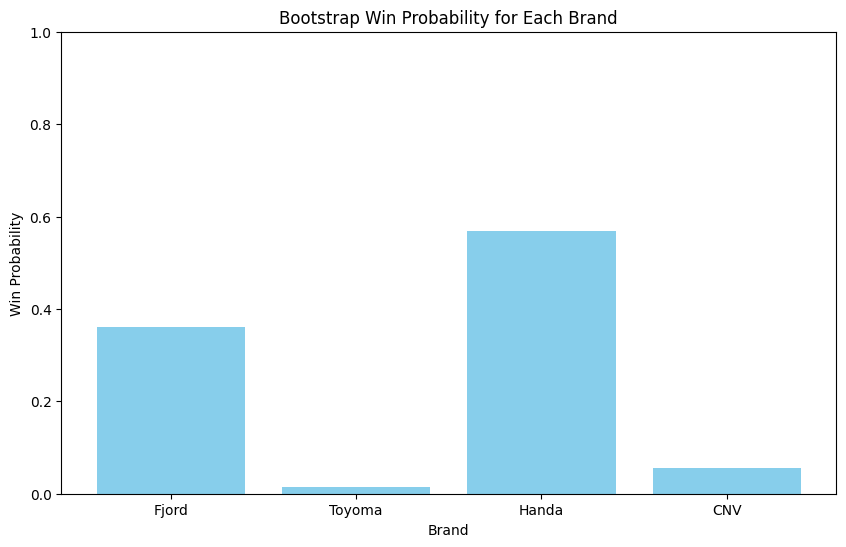

In [3]:
def bootstrap_best_repair_time(dataframe, num_repetitions):
    """
    Performs a bootstrap analysis to determine the win probability for each brand
    based on the best (highest) average repair time.

    Args:
        dataframe: A pandas DataFrame with 'Brand' and 'Time_to_Repair' columns.
        num_repetitions: The number of bootstrap repetitions to perform.

    Returns:
        A dictionary where keys are brand names and values are their win probabilities.
    """
    win_counts = {}
    brands = dataframe['Brand'].unique()
    for brand in brands:
        win_counts[brand] = 0

    for _ in range(num_repetitions):
        # Resample with replacement
        bootstrapped_df = dataframe.sample(n=len(dataframe), replace=True)

        # Compute the best brand for the bootstrapped sample
        best_brand, _ = compute_best_repair_time(bootstrapped_df)

        # Increment the win count for the winning brand
        win_counts[best_brand] += 1

    # Calculate win probabilities
    win_probabilities = {brand: count / num_repetitions for brand, count in win_counts.items()}

    return win_probabilities

# Perform the bootstrap analysis
num_repetitions = 1000
win_probs = bootstrap_best_repair_time(car_df, num_repetitions)

# Print the win probabilities
print("Win Probabilities for Each Brand:")
for brand, prob in win_probs.items():
    print(f"{brand}: {prob:.2f}")

# Plot the win probabilities
import matplotlib.pyplot as plt

brands = list(win_probs.keys())
probabilities = list(win_probs.values())

plt.figure(figsize=(10, 6))
plt.bar(brands, probabilities, color='skyblue')
plt.xlabel('Brand')
plt.ylabel('Win Probability')
plt.title('Bootstrap Win Probability for Each Brand')
plt.ylim(0, 1)
plt.show()

An intuitive explanation of what is happening here is that sometimes some datapoints will be included multiple times or completely excluded. What this tells us is "how much do the exact results we got depend on the data being exactly the way we got it and how much would it change if a few datapoints changed". In this case, it shows us that most variations of the dataset still end up with Handa winning (which is to be expected, the measurement you get from the bootstrap will always be close to the data you actually saw), but that there is still some uncertainty and Fjord would also win in a substantial number of cases. In a real-world setting, this may spur you to collect a bit more data, but focus on only Handa and Fjord for further data collection.

This is great, but repeated resampling from the entire dataset is a bottleneck, because we are basically accessing and loading random elements in the dataset over and over. It would be nice if we had an alternative that allows us to access the data in a predictable pattern, so we can ideally only look at each datapoint once when we compute a statistic.

## Enter the Bayesian Bootstrap

Instead of resampling, the Bayesian Bootstrap takes a different approach. It works by assigning a random, positive weight to each of your original datapoints. These weights are probabilities drawn from a [Dirichlet distribution](https://en.wikipedia.org/wiki/Dirichlet_distribution), which is a continuous probability distribution over probability distributions. Essentially, the Bayesian Bootstrap assigns each datapoint a probability to be included in the final computation and then uses those probabilities as weights. This means that it provides a 'smoother' version of the bootstrap in which all datapoints are always included in the computation. So we can access the data in a predictable manner - a one-time pass - if we know how to compute the weights in a straightforward way.

## The Stick-Breaking Construction

The real magic for efficient implementations of the Bayesian Bootstrap comes from something called the [stick-breaking](https://en.wikipedia.org/wiki/Dirichlet_process#The_stick-breaking_process) construction. It's a simple, sequential way to get draws from the Dirichlet distribution without needing to consider all datapoints at once. Imagine a stick of length 1 (representing the total probability). You can break off a random piece, and that piece is the weight for your first datapoint. Then, you take the remaining part of the stick and repeat the process to get the weight for the second datapoint, and so on. If you decide the amount to "break off" by using a Beta distribution (a special case of the Dirichlet distribution with two categories (K=2)), then the resulting assignments come out as the right weights for the Bayesian Bootstrap.

More formally, the weights $W_1,W_2,...,W_N$ are constructed as follows:

1.  For $i=1,...,N-1$, draw a random variable $Y_i \sim \text{Beta}(1,N-i)$ (so a beta draw weighted with 1 for the current element and $N-i=$ the number of remaining elements that need weights).
1.  Set $W_1=Y_1$
1.  Set $W_i=(Y_i \prod_{j=1}^{i-1}(1-Y_j))$ for $i=2,...,N-1$
1.  Set $W_N=1-\sum_{i=1}^{N-1}W_i$

This is a sequential process and for a statistic that is a simple weighted sum you can compute the result on-the-fly. This means we can load a few entries into memory, process them and then forget them or remove them from memory.

So this should be much faster than the plain bootstrap, right? However, the Pandas library is pretty efficient at offloading computations to efficient C++ and you would only see an advantage with datasets that are far too large for a small demo. So, we will need one more trick.

## Mixing and Matching

The observation we need in order to get more efficient is the fact that we can "break the stick" in any way we want. In the above, we said:

"draw a random variable $Y_i \sim \text{Beta}(1,N-i)$"

This corresponds to "break off a piece of stick for the next entries". Here the "stick" is the probability mass we have left to distribute. However, we can take some probability mass and "break it" into larger pieces that correspond to more entries. So if we want to assign probability to a chunk of $k$ entries starting at position $i$ in a dataset of $N$ total entries, we draw $Y \sim \text{Beta}(k,\, N-i-k)$ — the first parameter is the chunk size and the second is the number of remaining entries after the chunk. We can then keep splitting the probability for each subgroup further, until we have broken it down into single pieces.

So, what we are going to do is:

1. Grab a slice of data (as much as will fit in memory, or in our case enough for the demo).
1. Compute a weight for that slice as a whole.
1. Run a simple Bayesian Bootstrap on that slice, as this will be nice and fast
1. Weight the results for the slice, and sum it with the total results as we go along

Here is an illustration:

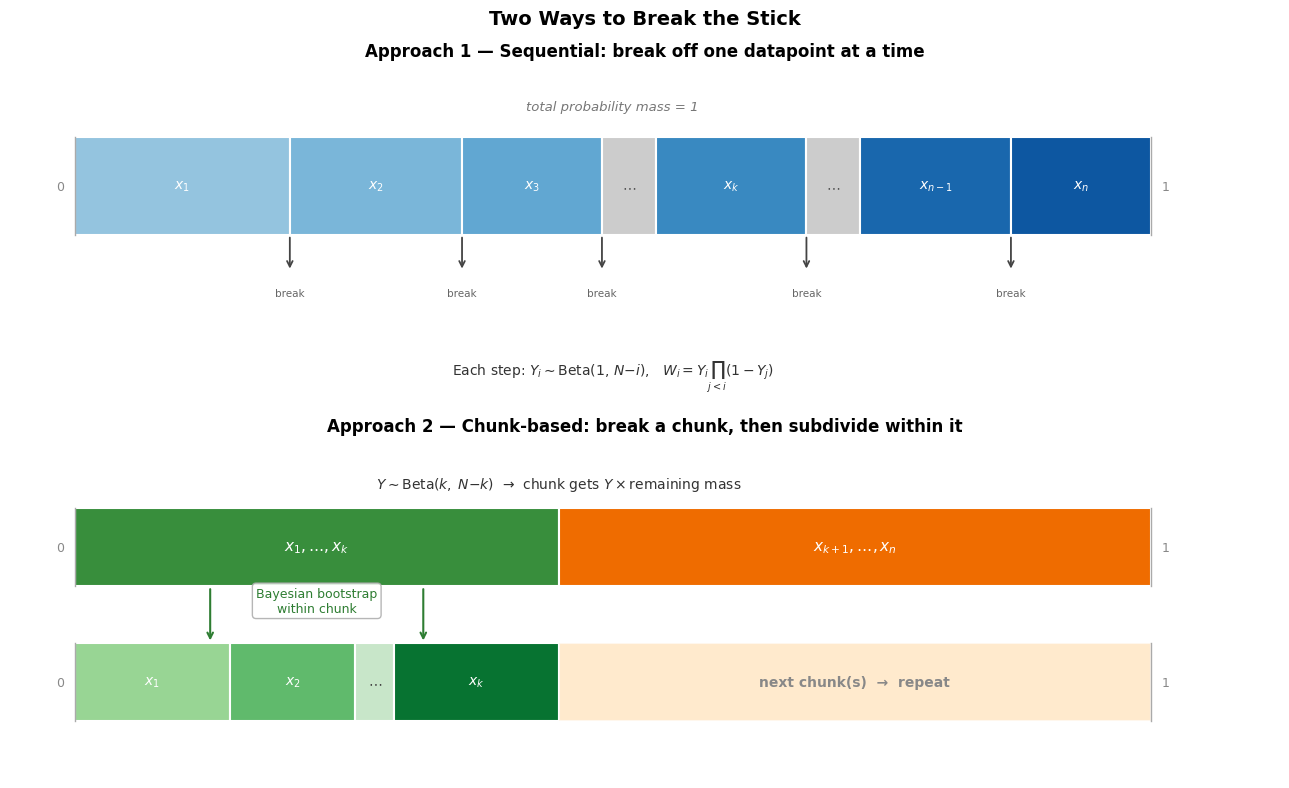

In [4]:
# this code is just here to draw the illustration

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), facecolor='white')
fig.subplots_adjust(hspace=0.55)

# ── Shared helper ─────────────────────────────────────────────────────────────
def draw_segment(ax, x, y, w, h, color, label='', lcolor='white', fs=11, alpha=1.0):
    ax.add_patch(patches.Rectangle(
        (x, y), w, h, linewidth=1.5, edgecolor='white',
        facecolor=color, alpha=alpha, zorder=2))
    if label:
        ax.text(x + w / 2, y + h / 2, label, ha='center', va='center',
                fontsize=fs, color=lcolor, fontweight='bold', zorder=3)

# ── Panel 1: Sequential stick-breaking ───────────────────────────────────────
ax1.set_title('Approach 1 — Sequential: break off one datapoint at a time',
              fontsize=12, fontweight='bold', pad=8)

# Illustrative segment widths (hardcoded so the figure is always the same)
seg_w = np.array([0.20, 0.16, 0.13, 0.05, 0.14, 0.05, 0.14, 0.13])
seg_labels = ['$x_1$', '$x_2$', '$x_3$', r'$\cdots$', '$x_k$',
              r'$\cdots$', '$x_{n-1}$', '$x_n$']
blues = plt.cm.Blues(np.linspace(0.40, 0.85, len(seg_w)))

BY, BH = 0.50, 0.32   # bar origin-y and height
x = 0.0
for i, (w, lbl, col) in enumerate(zip(seg_w, seg_labels, blues)):
    is_dots = (lbl == r'$\cdots$')
    fc = '#cccccc' if is_dots else col
    lc = '#555555' if is_dots else 'white'
    draw_segment(ax1, x, BY, w, BH, fc, lbl, lc, fs=10)
    # downward "break" arrow at each right boundary (skip dots and last segment)
    if not is_dots and i < len(seg_w) - 1:
        bx = x + w
        ax1.annotate('', xy=(bx, BY - 0.12), xytext=(bx, BY),
                     arrowprops=dict(arrowstyle='->', color='#444', lw=1.3), zorder=4)
        ax1.text(bx, BY - 0.20, 'break', ha='center', fontsize=7.5, color='#666')
    x += w

# Ruler ticks and formula
ax1.plot([0, 0], [BY, BY + BH], color='#aaa', lw=1)
ax1.plot([1, 1], [BY, BY + BH], color='#aaa', lw=1)
ax1.text(-0.01, BY + BH / 2, '0', ha='right', va='center', fontsize=9, color='#888')
ax1.text( 1.01, BY + BH / 2, '1', ha='left',  va='center', fontsize=9, color='#888')
ax1.text(0.5, BY + BH + 0.09, 'total probability mass = 1',
         ha='center', fontsize=9.5, color='#777', style='italic')
ax1.text(0.5, 0.04,
         r'Each step: $Y_i \sim \mathrm{Beta}(1,\, N{-}i)$,'
         r'   $W_i = Y_i \prod_{j < i}(1 - Y_j)$',
         ha='center', fontsize=10, color='#333')
ax1.set_xlim(-0.06, 1.12); ax1.set_ylim(-0.05, 1.05); ax1.axis('off')

# ── Panel 2: Chunk-based stick-breaking ──────────────────────────────────────
ax2.set_title('Approach 2 — Chunk-based: break a chunk, then subdivide within it',
              fontsize=12, fontweight='bold', pad=8)

c1_w, c2_w = 0.45, 0.55   # chunk widths

# Level 1: coarse split
L1Y, L1H = 0.62, 0.26
draw_segment(ax2, 0.0,  L1Y, c1_w, L1H, '#388e3c', r'$x_1, \ldots, x_k$',     'white', fs=11)
draw_segment(ax2, c1_w, L1Y, c2_w, L1H, '#ef6c00', r'$x_{k+1}, \ldots, x_n$', 'white', fs=11)
ax2.text(c1_w, L1Y + L1H + 0.07,
         r'$Y \sim \mathrm{Beta}(k,\; N{-}k)$  →  chunk gets $Y \times \mathrm{remaining\ mass}$',
         ha='center', fontsize=10, color='#333')

# Connecting arrows from chunk 1 down to level 2
L2Y, L2H = 0.17, 0.26
for fx in [c1_w * 0.28, c1_w * 0.72]:
    ax2.annotate('', xy=(fx, L2Y + L2H), xytext=(fx, L1Y),
                 arrowprops=dict(arrowstyle='->', color='#2e7d32', lw=1.5), zorder=4)
ax2.text(c1_w / 2, (L1Y + L2Y + L2H) / 2 + 0.01,
         'Bayesian bootstrap\nwithin chunk', ha='center', fontsize=9, color='#2e7d32',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#aaa', alpha=0.85))

# Level 2: sub-breakdown of chunk 1
sub_w_raw = np.array([0.32, 0.26, 0.08, 0.34])
sub_w = sub_w_raw / sub_w_raw.sum() * c1_w
sub_labels = ['$x_1$', '$x_2$', r'$\cdots$', '$x_k$']
greens = plt.cm.Greens(np.linspace(0.40, 0.85, len(sub_w)))

x = 0.0
for w, lbl, col in zip(sub_w, sub_labels, greens):
    is_dots = (lbl == r'$\cdots$')
    fc = '#c8e6c9' if is_dots else col
    lc = '#444'   if is_dots else 'white'
    draw_segment(ax2, x, L2Y, w, L2H, fc, lbl, lc, fs=10)
    x += w

# Faded continuation box for chunk 2
draw_segment(ax2, c1_w, L2Y, c2_w, L2H, '#ffe0b2',
             'next chunk(s)  →  repeat', '#888', fs=10, alpha=0.65)

# Ruler ticks for both levels
for yb, yh in [(L1Y, L1H), (L2Y, L2H)]:
    ax2.plot([0, 0], [yb, yb + yh], color='#aaa', lw=1)
    ax2.plot([1, 1], [yb, yb + yh], color='#aaa', lw=1)
    ax2.text(-0.01, yb + yh / 2, '0', ha='right', va='center', fontsize=9, color='#888')
    ax2.text( 1.01, yb + yh / 2, '1', ha='left',  va='center', fontsize=9, color='#888')

ax2.set_xlim(-0.06, 1.12); ax2.set_ylim(-0.02, 1.10); ax2.axis('off')

plt.suptitle('Two Ways to Break the Stick', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The code to implement this approach is here:


Bayesian Bootstrap Win Probabilities (Slice-wise) for Each Brand:
Fjord: 0.33
Toyoma: 0.01
Handa: 0.60
CNV: 0.06


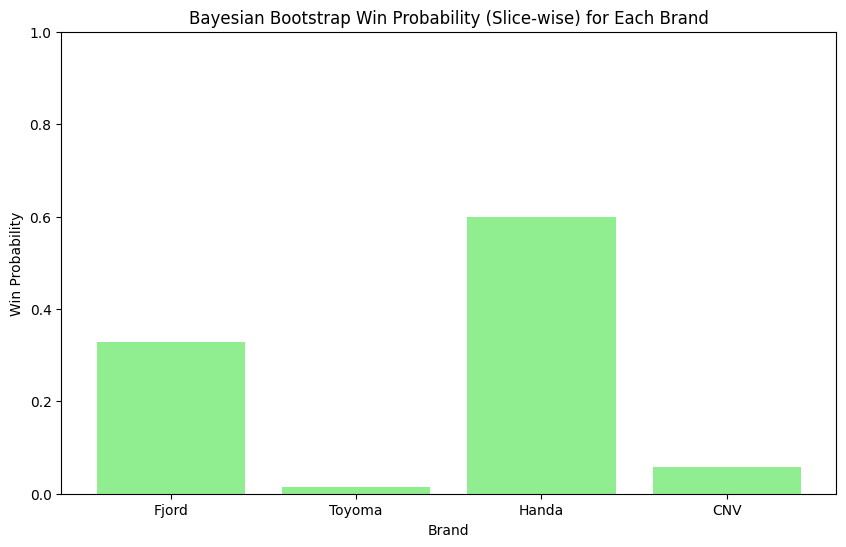

In [5]:
import scipy.stats as st
import math

def slice_wise_bootstrap(dataframe, num_repetitions, slice_size=1000):
    """
    Performs a slice-wise Bayesian bootstrap to calculate win probabilities
    for the brand with the highest average repair time.

    Args:
        dataframe (pd.DataFrame): The input DataFrame.
        num_repetitions (int): The number of bootstrap repetitions.
        slice_size (int): The size of each data slice.

    Returns:
        dict: A dictionary of win probabilities for each brand.
    """
    brands = dataframe['Brand'].unique()
    total_win_counts = {brand: 0 for brand in brands}

    for rep in range(num_repetitions):
        repair_times = {brand: 0.0 for brand in brands}
        sum_mass_per_brand = {brand: 0.0 for brand in brands}
        remaining_probability_mass = 1.0

        for i in range(0, len(dataframe), slice_size):
            # Explicitly create a copy of the slice to avoid SettingWithCopyWarning
            slice_df = dataframe.iloc[i:i+slice_size].copy()
            current_slice_size = len(slice_df)

            if len(dataframe) - (i + current_slice_size) <= 0:
                slice_prob = remaining_probability_mass
            else:
                beta_draw = st.beta.rvs(current_slice_size, len(dataframe) - (i + current_slice_size))
                slice_prob = beta_draw * remaining_probability_mass
                remaining_probability_mass *= (1 - beta_draw)

            # Assign new columns to the slice copy
            weights = np.random.dirichlet(np.ones(len(slice_df)))
            slice_df['weight'] = weights
            slice_df['weighted_time'] = slice_df['Time_to_Repair'] * slice_df['weight']

            grouped_sums = slice_df.groupby('Brand').agg(
                sum_weighted_time=('weighted_time', 'sum'),
                sum_weights=('weight', 'sum')
            )

            for brand in brands:
                sum_weighted_time = grouped_sums.loc[brand, 'sum_weighted_time'] if brand in grouped_sums.index else 0.0
                sum_weights = grouped_sums.loc[brand, 'sum_weights'] if brand in grouped_sums.index else 0.0

                repair_times[brand] += sum_weighted_time * slice_prob
                sum_mass_per_brand[brand] += sum_weights * slice_prob

        # Calculate win probabilities
        # Brands with zero probability mass get 0 so they never win
        all_repair_times = {brand: (repair_times[brand] / sum_mass_per_brand[brand]) if sum_mass_per_brand[brand] > 0 else 0 for brand in brands}
        winning_brand = max(all_repair_times, key=all_repair_times.get)
        total_win_counts[winning_brand] += 1

    win_probabilities = {brand: count / num_repetitions for brand, count in total_win_counts.items()}

    return win_probabilities


# Perform the Bayesian Bootstrap analysis
num_repetitions = 1000
win_probs_bayesian_slice = slice_wise_bootstrap(car_df, num_repetitions, slice_size=1000)

# Print the win probabilities
print("\nBayesian Bootstrap Win Probabilities (Slice-wise) for Each Brand:")
for brand, prob in win_probs_bayesian_slice.items():
    print(f"{brand}: {prob:.2f}")

brands = list(win_probs_bayesian_slice.keys())
probabilities = list(win_probs_bayesian_slice.values())

plt.figure(figsize=(10, 6))
plt.bar(brands, probabilities, color='lightgreen')
plt.xlabel('Brand')
plt.ylabel('Win Probability')
plt.title('Bayesian Bootstrap Win Probability (Slice-wise) for Each Brand')
plt.ylim(0, 1)
plt.show()

You will note that this just happens to give pretty much the same result as the original, basic bootstrap - which is to be expected if what we are doing is correct. After all, two correct methods should arrive at the same answers, even if they use approximations due to sampling.

I will leave the proof that we are doing the right thing here as an exercise for the reader - or you can contact me to sit down over coffee and talk it through. :)

As a final step, you can further optimize the above for efficiency on a single slice by making use of vector math using numpy. This optimized version will be easier to understand after reading the non-optimized version. It is lightning-fast and still preserves the nice property that data is processed slice-by-slice, instead of fetching randomly selected rows of data.

Vectorized Bayesian Bootstrap Win Probabilities for Each Brand:
Fjord: 0.35
Toyoma: 0.01
Handa: 0.57
CNV: 0.07


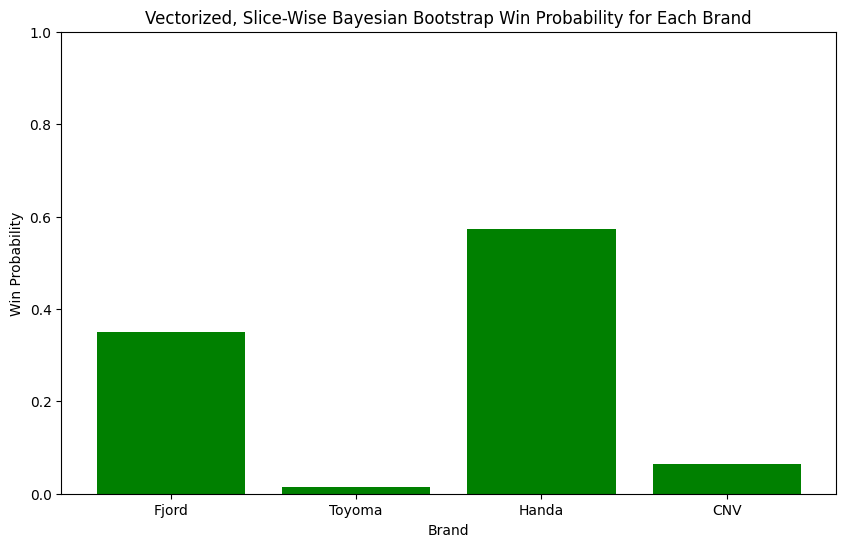

In [6]:
def slice_wise_bootstrap_vectorized(dataframe, num_repetitions, slice_size=1000):
    """
    Performs a slice-wise Bayesian bootstrap using a vectorized approach.
    This method avoids slow Python loops over DataFrame slices.
    """
    brands = dataframe['Brand'].unique()
    total_win_counts = {brand: 0 for brand in brands}

    # Pre-map brands to integer indices for efficient NumPy operations
    brand_map = {brand: i for i, brand in enumerate(brands)}
    brand_indices = np.array([brand_map[b] for b in dataframe['Brand'].values])
    time_to_repair = dataframe['Time_to_Repair'].values

    num_rows = len(dataframe)
    num_slices = math.ceil(num_rows / slice_size)

    for rep in range(num_repetitions):
        repair_times = np.zeros(len(brands))
        sum_mass_per_brand = np.zeros(len(brands))
        remaining_probability_mass = 1.0

        for i in range(num_slices):
            start = i * slice_size
            end = min(start + slice_size, num_rows)
            current_slice_size = end - start

            if i == num_slices - 1:
                slice_prob = remaining_probability_mass
            else:
                beta_draw = np.random.beta(current_slice_size, num_rows - end)
                slice_prob = beta_draw * remaining_probability_mass
                remaining_probability_mass *= (1 - beta_draw)

            # Use NumPy's vectorized operations directly on the slice
            slice_brand_indices = brand_indices[start:end]
            slice_time_to_repair = time_to_repair[start:end]

            weights = np.random.dirichlet(np.ones(current_slice_size))

            # Use a temporary array for weighted times
            weighted_time = slice_time_to_repair * weights

            # Group and sum using a pivot-like operation (pure NumPy)
            for brand_idx in range(len(brands)):
                mask = slice_brand_indices == brand_idx
                repair_times[brand_idx] += np.sum(weighted_time[mask]) * slice_prob
                sum_mass_per_brand[brand_idx] += np.sum(weights[mask]) * slice_prob

        # Calculate win probabilities
        # Brands with zero probability mass get -inf so they never win
        all_repair_times = np.full(len(brands), -np.inf)

        # Avoid division by zero with a mask
        non_zero_mass = sum_mass_per_brand > 0
        all_repair_times[non_zero_mass] = repair_times[non_zero_mass] / sum_mass_per_brand[non_zero_mass]

        # Find the winning brand index and increment the count
        winning_brand_idx = np.argmax(all_repair_times)
        total_win_counts[brands[winning_brand_idx]] += 1

    win_probabilities = {brand: count / num_repetitions for brand, count in total_win_counts.items()}
    return win_probabilities


# Perform the Bayesian Bootstrap analysis with the vectorized solution
num_repetitions = 1000
win_probs_bayesian_slice = slice_wise_bootstrap_vectorized(car_df, num_repetitions, slice_size=1000)

# Print the win probabilities
print("Vectorized Bayesian Bootstrap Win Probabilities for Each Brand:")
for brand, prob in win_probs_bayesian_slice.items():
    print(f"{brand}: {prob:.2f}")

# Plot the win probabilities
brands = list(win_probs_bayesian_slice.keys())
probabilities = list(win_probs_bayesian_slice.values())

plt.figure(figsize=(10, 6))
plt.bar(brands, probabilities, color='green')
plt.xlabel('Brand')
plt.ylabel('Win Probability')
plt.title('Vectorized, Slice-Wise Bayesian Bootstrap Win Probability for Each Brand')
plt.ylim(0, 1)
plt.show()

This should give you a powerful tool to do statistics on very large datasets and it will work for almost any statistic you may care about. Note that there is nothing stopping you from doing the repeated trials for the bootstrap in multiple parallel loops for much faster processing times. Since the slices are processed in a way that is completely independent, you can also parallelize the slices as well - there is nearly infinite room from speeding up computation, should you have the resources to spare.

Have fun with this tool and let me know if you have any tricks to make this even faster.